In [327]:
import csv
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from tabulate import tabulate
from collections import defaultdict
from matplotlib import pyplot as plt
import re
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2
import copy
from matplotlib.ticker import FormatStrFormatter


In [356]:
# import tensorflow as tf

In [66]:
default_test_size = 0.3

In [399]:
dataset = pd.read_csv("augmented_df_data.csv")
# dataset = pd.read_csv("covid_screen_data_cleaned.csv")

df = dataset.copy()
data_df = dataset.drop(['Replicate', 'Conc.', 'batch'], axis=1)
# data_df = dataset.drop(['Replicates', 'Conc.'], axis=1)
print('variants:', df.target_vector.unique())
data_df.head()

variants: ['Beta' 'Delta' 'Omicron' 'WT']


,Unnamed: 0,target_vector,cAb7,cAb8,cAb9,cAb10,cAb13,cAb14,cAb15,cAb20,cAb21,cAb25,cAb26
0,1,Beta,3.922,3.410,2.164,1.631,2.148,2.601,2.572,4.168,3.982,3.195,4.268
1,2,Beta,3.679,2.986,1.279,0.942,1.873,2.034,1.625,3.737,3.520,2.679,3.716
2,3,Beta,3.283,2.540,1.378,0.000,1.867,1.362,1.016,3.282,3.212,2.219,3.286
3,4,Beta,2.805,2.188,0.000,0.000,0.000,0.000,0.000,2.903,2.485,1.715,2.970
4,5,Beta,2.881,2.079,0.000,0.000,0.000,0.512,0.495,2.508,2.282,1.575,2.779


In [400]:
data_df.columns

Index(['Unnamed: 0', 'target_vector', 'cAb7', 'cAb8', 'cAb9', 'cAb10', 'cAb13',
       'cAb14', 'cAb15', 'cAb20', 'cAb21', 'cAb25', 'cAb26'],
      dtype='object')

In [401]:
def Xy_split(df, y_column_name='target_vector'):
    X = df.loc[:, df.columns != y_column_name]
    y = df[y_column_name]
    return X, y

def target_split(df, target_name):
    df_no_target = df.loc[df["target_vector"] != target_name]
    df_target = df.loc[df["target_vector"] == target_name]
    return df_no_target, df_target


# Test/Train/Target split!
def test_train_target_split(df, target_variant, test_size):
    global do_print
    
    print(f'test/train split size = {test_size}') if do_print else None
    print(f'target variant = {target_variant}\n') if do_print else None
    
    no_target, target = target_split(df=df, target_name=target_variant)
    no_target_train, no_target_test = train_test_split(no_target, test_size=test_size, random_state=2023)

    out_dict = {'non_target_train_samples': no_target_train,
                'non_target_test_samples': no_target_test,
                'target_samples': target,
                'non_target_samples': no_target
               }
    
    print(f'dataset: {df.shape}\n')  if do_print else None
    for k, d in out_dict.items():
        r, c = d.shape
        print(f"{k}: {r} x {c}") if do_print else None
    print() if do_print else None
    return out_dict


In [404]:
def train_LogRegTTT_model(df, target, test_size=default_test_size):
    data_dict = test_train_target_split(df=df, target_variant=target, test_size=test_size)
    
    # training the LogReg model
    train_X, train_y = Xy_split(data_dict['non_target_train_samples'])
    model = LogisticRegression(max_iter=1000)
    model.fit(train_X, train_y)
    return model, data_dict

def generate_results_df(model, df, target, thr):
    X, y = Xy_split(df)
    
    y_pred = model.predict(X)
    y_pred_prob = model.predict_proba(X)

    results = pd.DataFrame(y_pred_prob, columns=model.classes_)
    results['real'] = list(y)
    results['pred_model'] = y_pred
    results['conf'] = y_pred_prob.max(axis=1)
    results['conf_flag'] = y_pred_prob.max(axis=1) > thr 
    results['pred_from_conf'] = results.apply(lambda row: row['pred_model'] if row['conf_flag'] else target, axis=1)
    results = results.drop('conf', axis=1)
    return results

def generate_mahalanobis_resutls_df(df, target, thr, mean_distribution, inv_cov_matrix):
    def is_outlier(point, mean_distribution, inv_cov_matrix, threshold=thr):
        distance = mahalanobis(point, mean_distribution, inv_cov_matrix)
        p_value = 1 - chi2.cdf(distance, len(mean_distribution))
        if p_value < threshold:
            return target
        else:
            return 'not_an_outlier' 
    
    dfc = copy.deepcopy(df)
    dfx, dfy = Xy_split(df)
    dfc['is_outlier'] = dfx.apply(lambda row: is_outlier(row, mean_distribution, inv_cov_matrix), axis=1)
    results = pd.DataFrame()
    results['real'] = list(dfc['target_vector'])
    results['pred_from_conf'] = list(dfc['is_outlier'])
    return results
    
    
    
def calculate_prefromance(results, description=None):
    L = len(results)
    sum_true_preds = sum(results['real'] == results['pred_from_conf'])
    performance = 100*sum_true_preds/L
    
    if description:
        print(f'{description}-> {performance:.2f}% [{sum_true_preds}/{L}]')
    return performance


            Beta      Delta    Omicron         WT
0.990  14.980159   9.027778   9.523810  10.317460
0.991  15.376984   9.226190  10.218254  11.408730
0.992  16.369048   9.821429  10.714286  12.202381
0.993  16.666667  10.317460  11.111111  13.095238
0.994  17.658730  11.210317  12.202381  13.492063
0.995  18.253968  11.507937  12.896825  15.079365
0.996  19.146825  12.202381  14.087302  16.567460
0.997  20.039683  13.888889  15.773810  17.956349
0.998  21.825397  15.376984  17.956349  19.642857
0.999  24.206349  16.567460  21.726190  22.817460
1.000  27.976190  18.452381  25.595238  27.976190


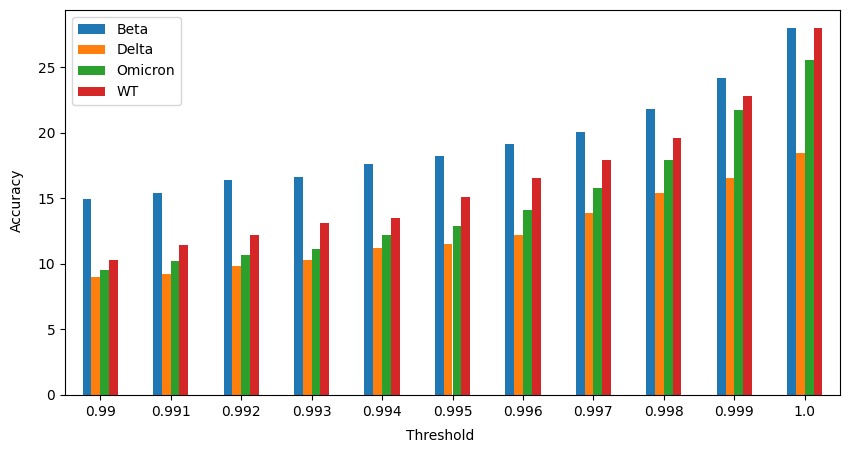

In [406]:
targets_vec = ['Beta', 'Delta', 'Omicron', 'WT']
thr_list = np.linspace(0.99, 1, num=11).tolist()

target_results_df = pd.DataFrame()

for t in targets_vec:
    print('-------')  if do_print else None
    
    data_dict = test_train_target_split(df=data_df, target_variant=t, test_size=0.3)
    train_X, train_y = Xy_split(data_dict['non_target_samples'])
    cov_matrix = np.cov(train_X.values.T)
    inv_cov_matrix = np.linalg.inv(cov_matrix)
    mean_distribution = train_X.mean().values
    target_perf_list = []
    for thr in thr_list:
        thr_results = generate_mahalanobis_resutls_df(df=data_df, target=t, thr=thr, 
                                                      mean_distribution=mean_distribution, 
                                                      inv_cov_matrix=inv_cov_matrix)
        perf = calculate_prefromance(thr_results)
        target_perf_list.append(perf)
    target_results_df[t]= target_perf_list 

    target_results_df.index = thr_list
print('\n\t_results_df:\n', target_results_df) if do_print else None
fig, ax = plt.subplots(1,1, figsize=(10, 5)) 
target_results_df.plot.bar(ax=ax, rot=0, width=0.5)
fig.text(0.5, 0.02, 'Threshold', ha='center')
fig.text(0.07, 0.5, 'Accuracy', va='center', rotation='vertical')

print(target_results_df)


In [333]:



# input_layer = Input(shape=(10,))
# encoded = Dense(5, activation='relu')(input_layer)
# decoded = Dense(10, activation='sigmoid')(encoded)
# autoencoder = Model(input_layer, decoded)

# autoencoder.compile(optimizer='adam', loss='mean_squared_error')
# autoencoder.fit(df, df, epochs=50, batch_size=32, shuffle=True, validation_data=(df, df))

# # Use the autoencoder to reconstruct the DataFrame
# reconstructed = autoencoder.predict(df)
# reconstruction_error = ((df - reconstructed) ** 2).mean(axis=1)
# threshold = reconstruction_error.quantile(0.99)
# ood_indices = reconstruction_error[reconstruction_error > threshold].index

In [350]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
import pandas as pd
import numpy as np

target = 'Beta'

data_dict = test_train_target_split(df=data_df, target_variant=target, test_size=0.3)
train_X, train_y = Xy_split(data_dict['non_target_samples'])
test_X, test_y = Xy_split(data_dict['target_samples'])

# Initialize and fit the Isolation Forest model
clf = IsolationForest(random_state=0)
clf.fit(train_X)

# Predict on the test set
res = clf.predict(test_X) == -1
results = pd.DataFrame()
results['real'] = list(test_y)
results['pred_from_conf'] = list(res)


L = len(results)
    
sum_true_preds = sum((results['real'] == target) & (results['pred_from_conf'] == True))
performance = 100*sum_true_preds/L

print(performance, sum_true_preds, L)

21.705426356589147 56 258


In [410]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import pandas as pd

target = 'Omicron'

# Assume 'df' is your DataFrame and 'label' is the column with binary labels
X = data_df.drop('target_vector', axis=1)  # Features
y = (data_df['target_vector'] == target).astype(int)  # Labels

# Split the data into training and test sets
data_dict = test_train_target_split(df=data_df, target_variant=target, test_size=0.3)
train_X, train_y = Xy_split(data_dict['non_target_samples'])
test_X, test_y = Xy_split(data_dict['target_samples'])

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Random Forest model
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
rf.fit(train_X, train_y)

# Predict on the test set
y_pred = rf.predict(test_X)


results = pd.DataFrame()
results['real'] = list(test_y)
results['pred_from_conf'] = list(y_pred)
L = len(y_pred)
    
sum_true_preds = sum((results['real'] == results['pred_from_conf']))
print(sum_true_preds,L)
performance = 100*sum_true_preds/L

print(performance, sum_true_preds, L)

0 258
0.0 0 258


In [419]:
probabilities

array([[0.75, 0.12, 0.13],
       [0.96, 0.03, 0.01],
       [0.94, 0.03, 0.03],
       ...,
       [0.  , 0.02, 0.98],
       [0.  , 0.03, 0.97],
       [0.  , 0.  , 1.  ]])

In [422]:
data_dict = test_train_target_split(df=data_df, target_variant=target, test_size=0.3)
train_X, train_y = Xy_split(data_dict['non_target_train_samples'])
nttest_X, nttest_y = Xy_split(data_dict['non_target_test_samples'])
test_X, test_y = Xy_split(data_dict['target_samples'])


rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(train_X, train_y)

y_pred = rf_clf.predict(test_X)
ntypred = rf_clf.predict(nttest_X)

# print(classification_report(test_y, y_pred))

probabilities = rf_clf.predict_proba(data_df.drop('target_vector', axis=1))

# Calculate the maximum predicted probability across the non-outlier classes for each instance
max_probs = probabilities.max(axis=1)

# Define a threshold for considering a prediction as an outlier. This should be set based on your specific problem.
threshold = 0.6

# Instances from the full dataset that have a max probability below the threshold are considered outliers
predicted_outliers1 = data_df[max_probs < threshold]

print(predicted_outliers.shape, predicted_outliers)
results = pd.DataFrame()
results1 = pd.DataFrame()
results1['real'] = list(ntypred)
results['pred_from_conf'] = list(predicted_outliers)
L = len(y_pred)
    
sum_true_preds = sum((predicted_outliers['target_vector'] == target))
sum_true_preds2 = sum(results1['real'] == list(nttest_y))
print(sum_true_preds2,L)
performance = 100*sum_true_preds/L
performance2 = 100*sum_true_preds2/L

print(performance, sum_true_preds, L)

print(performance2, sum_true_preds2, L)

(158, 13)      Unnamed: 0 target_vector   cAb7   cAb8   cAb9  cAb10  cAb13  cAb14  \
144         145       Omicron  3.797  1.981  0.699  0.000  0.000  1.065   
145         146       Omicron  3.077  1.503  0.000  0.000  0.000  0.000   
146         147       Omicron  3.236  1.451  0.000  0.000  0.000  0.000   
147         148       Omicron  2.866  0.000  0.000  0.000  0.000  0.000   
148         149       Omicron  2.235  0.000  0.000  0.000  0.000  0.000   
..          ...           ...    ...    ...    ...    ...    ...    ...   
936         937       Omicron  3.069  1.488  0.000  0.000  0.000  0.000   
937         938       Omicron  3.323  1.860  0.000  0.000  0.000  0.778   
938         939       Omicron  3.323  1.860  0.000  0.000  0.000  0.778   
939         940       Omicron  3.592  0.000  0.000  1.614  0.000  0.243   
940         941       Omicron  4.091  2.821  0.778  1.672  0.845  0.889   

     cAb15  cAb20  cAb21  cAb25  cAb26  
144  0.000  2.537  1.400  0.000  3.365  
145  0.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report
import pandas as pd

# Assume 'df' is your DataFrame and 'label' is the column with binary labels
X = df.drop('label', axis=1)  # Features
y = df['label']  # Labels

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Support Vector Classifier model
svc = SVC()

# Train the model
svc.fit(X_train, y_train)

# Predict on the test set
y_pred = svc.predict(X_test)

# Print the classification report
print(classification_report(y_test, y_pred))

In [145]:
def LogReg_TTT(df, target, thr, test_size=default_test_size, print_results_table=False):
    global do_print
    print(f'confidence threshold = {thr}')  if do_print else None
    model, data_dict = train_LogRegTTT_model(df, target)
    
    # generating the results dataframes
    non_target_test_results = generate_results_df(model, data_dict['non_target_test_samples'], target, thr)
    target_results = generate_results_df(model, data_dict['target_samples'], target, thr)
    
    # calculating the performance
    non_target_test_perf = calculate_prefromance(results=non_target_test_results, description="Performance on the test samples of the non_target dataset ")
    target_perf = calculate_prefromance(results=target_results, description="Performance on the target samples ")

    if print_results_table:
        print(tabulate(no_target_test_results, headers='keys', tablefmt='psql', floatfmt=".2f"), '\n\n')
        print(tabulate(target_test_results, headers='keys', tablefmt='psql', floatfmt=".2f"),)
    
    out_dict = {'non_target_test_results': non_target_test_results,
                'target_results': target_results,
                'non_target_test_perf': non_target_test_perf,
                'target_perf': target_perf        
    }
    return data_dict, out_dict, model


In [146]:
# now let's test it....

confidence_threshold = 0.5
target = 'Omicron'

data_dict, LogReg_TTT_dict, LogRegTTT_model = LogReg_TTT(df=data_df, target=target, thr=confidence_threshold)


Performance on the test samples of the non_target dataset -> 55.56% [125/225]
Performance on the target samples -> 36.05% [93/258]


In [147]:
# print(LogReg_TTT_dict['target_results'])

In [148]:
new_data_df = data_df.loc[:, ['Unnamed: 0', 'target_vector', 'cAb7', 'cAb14', 'cAb21', 'cAb26']]
new_features_vec = ['Unnamed: 0', 'cAb7', 'cAb14', 'cAb21', 'cAb26']
new_data_df.shape

(1008, 6)

In [177]:
nt_results_df

,Beta,Delta,Omicron,WT
0.0,68.348624,64.777328,64.444444,59.174312
0.1,68.348624,64.777328,64.444444,59.174312
0.2,68.348624,64.777328,64.444444,59.174312
0.3,68.348624,64.777328,64.444444,59.174312
0.4,66.972477,62.753036,60.888889,55.045872
0.5,56.422018,51.821862,55.555556,43.119266
0.6,43.577982,37.651822,43.111111,31.651376
0.7,34.403670,25.506073,31.111111,22.935780
0.8,24.770642,13.765182,23.555556,16.972477
0.9,11.926606,6.882591,10.666667,6.422018


In [150]:
# t_results_df['Omicron']

In [151]:
conc = [0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]
def whats_the_best_results(nt_results_df, t_results_df, conc):
    best3t = t_results_df['Omicron'].nlargest(3)
    best3nt = nt_results_df['Omicron'].nlargest(3)
    best3t_ind = t_results_df['Omicron'].nlargest(3).index
    best3nt_ind = nt_results_df['Omicron'].nlargest(3).index
#     print(best3t, best3nt, best3t_ind, best3nt_ind)
    loss = []
    for i in conc: 
        loss.append((200 - t_results_df['Omicron'][i] - nt_results_df['Omicron'][i])**4 
                    + (100-t_results_df['Omicron'][i])**2 + (100 - nt_results_df['Omicron'][i])**2) 
    
    return loss
loss = whats_the_best_results(nt_results_df, t_results_df,conc)
ind = loss.index(min(loss))
print(conc[ind])

0.8


In [179]:
do_print = False
conf_vec = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
def run_confidence_scan(input_df, conf_vec):
    targets_vec = ['Beta', 'Delta', 'Omicron', 'WT']
    features_vec = [col for col in input_df.columns if col != 'target_vector']

    nt_results_df = pd.DataFrame()
    t_results_df = pd.DataFrame()


    for t in targets_vec:
        print('-------')  if do_print else None
        nt_perf_list = []
        t_perf_list = []

        model, data_dict = train_LogRegTTT_model(df=input_df, target=t) #here

        # feature coefs/importance
        avg_coef = np.mean(np.abs(model.coef_), axis=0)
        coef_df = pd.DataFrame({'Feature': features_vec,'Importance': avg_coef}) #here

        # confidence screen results
        for c in conf_vec:
            nt_results = generate_results_df(model, data_dict['non_target_test_samples'], t, c)
            t_results = generate_results_df(model, data_dict['target_samples'], t, c)

            nt_perf = calculate_prefromance(nt_results)
            t_perf = calculate_prefromance(t_results)

            nt_perf_list.append(nt_perf)
            t_perf_list.append(t_perf)

        nt_results_df[t]= nt_perf_list 
        t_results_df[t]= t_perf_list 

    nt_results_df.index = conf_vec
    t_results_df.index = conf_vec
    print('nt_results_df:\n', nt_results_df) if do_print else None
    print('\n\nt_results_df:\n', t_results_df) if do_print else None
    fig, axes = plt.subplots(2,1, figsize=(10, 5)) 
    nt_results_df.plot.bar(ax=axes[0], rot=0,width=0.5)
    t_results_df.plot.bar(ax=axes[1], rot=0, width=0.5)
    fig.text(0.5, 0.02, 'Confidence Threshold', ha='center')
    fig.text(0.07, 0.5, 'Accuracy', va='center', rotation='vertical')
    return nt_results_df, t_results_df

best conf is: 0.8
target:94.07398392151228 
and non target 10.215509663360942
avg = 52.144746792436614


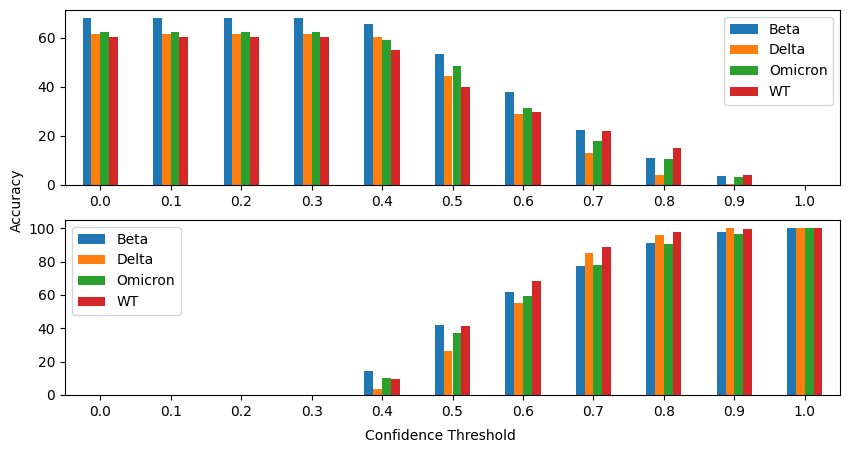

In [180]:
nt_results_df, t_results_df = run_confidence_scan(new_data_df,conf_vec)
loss = whats_the_best_results(nt_results_df, t_results_df,conf_vec)
ind = loss.index(min(loss))
best_conf = conf_vec[ind]
print(f'''best conf is: {best_conf}
target:{np.mean(t_results_df.iloc[ind])} 
and non target {np.mean(nt_results_df.iloc[ind])}
avg = {np.mean([np.mean(t_results_df.iloc[ind]), np.mean(nt_results_df.iloc[ind])])}''')

best conf is: 0.8
target:91.99361010465383 
and non target 19.765964251961357
avg = 55.879787178307595


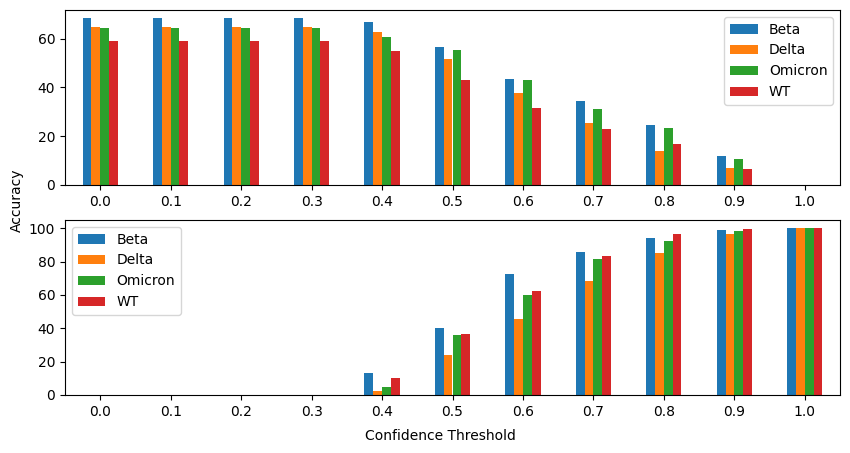

In [178]:
nt_results_df, t_results_df = run_confidence_scan(data_df,conf_vec)
loss = whats_the_best_results(nt_results_df, t_results_df,conf_vec)
ind = loss.index(min(loss))
best_conf = conf_vec[ind]
print(f'''best conf is: {best_conf}
target:{np.mean(t_results_df.iloc[ind])} 
and non target {np.mean(nt_results_df.iloc[ind])}
avg = {np.mean([np.mean(t_results_df.iloc[ind]), np.mean(nt_results_df.iloc[ind])])}''')

In [182]:
data_dict.keys()

dict_keys(['non_target_train_samples', 'non_target_test_samples', 'target_samples'])

In [142]:
confidence_threshold = 0.8

for t in targets_vec:
    _, _, model = LogReg_TTT(df=data_df, target=t, thr=confidence_threshold)

    avg_coef = np.mean(np.abs(model.coef_), axis=0)
    features_vec = [col for col in data_df.columns if col != 'target_vector']

    coef_df = pd.DataFrame({'Feature': features_vec,'Importance': avg_coef})
    sorted_coef_df = coef_df.sort_values(by='Importance', ascending=False)


confidence threshold = 0.8
test/train split size = 0.3
target variant = Beta

Performance on the test samples of the non_target dataset -> 24.77% [54/218]
Performance on the target samples -> 94.33% [266/282]
confidence threshold = 0.8
test/train split size = 0.3
target variant = Delta

Performance on the test samples of the non_target dataset -> 13.77% [34/247]
Performance on the target samples -> 84.95% [158/186]
confidence threshold = 0.8
test/train split size = 0.3
target variant = Omicron

Performance on the test samples of the non_target dataset -> 23.56% [53/225]
Performance on the target samples -> 92.25% [238/258]
confidence threshold = 0.8
test/train split size = 0.3
target variant = WT

Performance on the test samples of the non_target dataset -> 16.97% [37/218]
Performance on the target samples -> 96.45% [272/282]


<AxesSubplot: ylabel='Feature'>

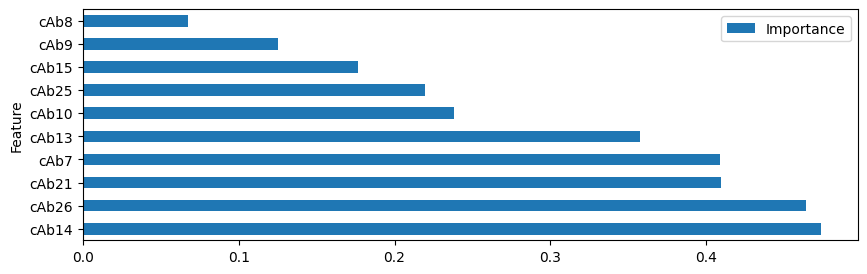

In [35]:
coefficients = model.coef_

nt_tr_X, nt_tr_y = Xy_split(data_dict['non_target_train_samples'])
t_X, t_y = Xy_split(data_dict['target_samples'])

avg_importance = np.mean(np.abs(coefficients), axis=0)
importance_df = pd.DataFrame({'Feature': nt_tr_X.columns,'Importance': avg_importance})
sorted_importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Select the top 10 features
top_10_features = sorted_importance_df.head(10)

top_10_features.plot(x='Feature', y='Importance', kind='barh', figsize=(10, 3))
# sorted_importance_df.plot(x='Feature', y='Importance', kind='barh', figsize=(10, 6))


In [36]:
importance_df['dAb'] = importance_df['Feature'].apply(lambda x: re.search(r'dAb(\d+)', x).group(1))

dAb_importance = importance_df.groupby('dAb')['Importance'].sum()

sorted_dAb_importance=dAb_importance.sort_values(ascending=False)
sorted_dAb_importance.plot(x='Feature', y='Importance', kind='barh', figsize=(10, 3))


AttributeError: 'NoneType' object has no attribute 'group'

In [23]:
best_dAb = sorted_dAb_importance.index[0]

X_no_omicron_important_features = nt_tr_X[nt_tr_X.columns[pd.Series(nt_tr_X.columns).str.startswith('dAb'+best_dAb)]]
X_omicron_important_features = t_X[t_X.columns[pd.Series(t_X.columns).str.startswith('dAb'+best_dAb)]]

best_dAb

NameError: name 'sorted_dAb_importance' is not defined

In [30]:
df_important = pd.merge(X_omicron_important_features, nt_tr_y)
X_omicron_important_features

MergeError: No common columns to perform merge on. Merge options: left_on=None, right_on=None, left_index=False, right_index=False

In [ ]:
target = 'Delta'
lr_model3 = LogisticRegression(max_iter=1000)
lr_model3.fit(X_no_omicron_important_features, y_no_omicron)

omicron_results_all_2 = create_results(model=lr_model3, X=X_omicron_important_features, y=y_omicron)

print(target)
omicron_results_all_2['pred_confidence'] = omicron_results_all_2.apply(
    lambda row: row['pred_model'] if row['confidence_flag'] else target, axis=1)

omicron_perf_all_2 = sum(omicron_results_all_2['real'] == omicron_results_all_2['pred_confidence'] )/len(omicron_results_all_2)*100


print(f'''Performance in Finding {target}, with only dAb{best_dAb}:
{sum(omicron_results_all_2['real'] == omicron_results_all_2['pred_confidence'] )} correct prediction 
in {len(omicron_results_all_2)} total samples ({omicron_perf_all_2:.2f}%)\n''')

print(tabulate(omicron_results_all_2, headers='keys', tablefmt='psql', floatfmt=(".1f", ".2f", ".2f", ".2f")), '\n\n')
target


In [ ]:
conf_vec = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
targets_vec = ['Beta', 'Delta', 'Omicron', 'WT']
features_vec = [col for col in data_df.columns if col != 'target_vector']

nt_results_df = pd.DataFrame()
t_results_df = pd.DataFrame()

for t in targets_vec:
    print('-------')
    nt_perf_list = []
    t_perf_list = []
    
    model, data_dict = train_LogRegTTT_model(df=data_df, target=t)
    
    # feature coefs/importance
    avg_coef = np.mean(np.abs(model.coef_), axis=0)
    coef_df = pd.DataFrame({'Feature': features_vec,'Importance': avg_coef})
    
    # confidence screen results
    for c in conf_vec:
        nt_results = generate_results_df(model, data_dict['non_target_test_samples'], t, c)
        t_results = generate_results_df(model, data_dict['target_samples'], t, c)
        
        nt_perf = calculate_prefromance(nt_results)
        t_perf = calculate_prefromance(t_results)

        nt_perf_list.append(nt_perf)
        t_perf_list.append(t_perf)
        
    nt_results_df[t]= nt_perf_list 
    t_results_df[t]= t_perf_list 
    
nt_results_df.index = conf_vec
t_results_df.index = conf_vec
print('nt_results_df:\n', nt_results_df)
print('\n\nt_results_df:\n', t_results_df)